# Predicción de la tasa de no promoción — Regresión lineal

En este notebook importamos datos de trayectorias 2011-2025 e intentamos construir un modelo de regresión lineal para la métrica calculada "tasa de no promoción" `nopromo / (promovidos + nopromo) * 100`. Se utilizan los últimos

Se deben subir todos los archivos y el año debe estar en su nombre o bien se puede indicar cual es cual en el diccionario de "ANIOS_MANUALES"


In [1]:
import re, io, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", 100)


## 1. Subir archivos
Subí un archivo por año. Se admiten CSV, XLS y XLSX.

In [2]:
uploaded = files.upload()
if not uploaded:
    raise ValueError("No se subieron archivos.")
print(list(uploaded.keys()))


Saving 2011 Trayectoria - agregada(in).csv to 2011 Trayectoria - agregada(in).csv
Saving 2012 Trayectoria - agregada(in).csv to 2012 Trayectoria - agregada(in).csv
Saving 2013 Trayectoria - agregada(in).csv to 2013 Trayectoria - agregada(in).csv
Saving 2014 Trayectoria - agregada(in).csv to 2014 Trayectoria - agregada(in).csv
Saving 2015 Trayectoria - agregada(in).csv to 2015 Trayectoria - agregada(in).csv
Saving 2016 Trayectoria - agregada(in).csv to 2016 Trayectoria - agregada(in).csv
Saving 2017 Trayectoria - agregada(in).csv to 2017 Trayectoria - agregada(in).csv
Saving 2018 Trayectoria - agregada(in).csv to 2018 Trayectoria - agregada(in).csv
Saving 2019 Trayectoria - agregada(in).csv to 2019 Trayectoria - agregada(in).csv
Saving 2020 Trayectoria - agregada(in).csv to 2020 Trayectoria - agregada(in).csv
Saving 2021 Trayectoria - agregada(in).csv to 2021 Trayectoria - agregada(in).csv
Saving 2022 Trayectoria - agregada(in).csv to 2022 Trayectoria - agregada(in).csv
Saving 2023 Tray

## 2. Configuración

`ALCANCE`: `"nacional"` o `"provincia"`.  
`AMBITO`: `"todos"`, `"urbano"` o `"rural"`.  
`SEXO`: `"total"` o `"mujeres"`.

Se agregan todos los años de estudio reconocidos. La comparación debe hacerse sobre una población y una definición homogéneas.


In [3]:
ALCANCE = "nacional"
PROVINCIA = "Chubut"
AMBITO = "todos"
SEXO = "total"

ANIOS_MANUALES = {
    # "archivo_sin_anio.csv": 2016,
}


## 3. Lectura y cálculo de la tasa

In [4]:
def detectar_anio(nombre):
    if nombre in ANIOS_MANUALES:
        return int(ANIOS_MANUALES[nombre])
    encontrados = re.findall(r"(?:19|20)\d{2}", nombre)
    if not encontrados:
        raise ValueError(f"No detecté el año en {nombre}. Agregalo a ANIOS_MANUALES.")
    return int(encontrados[-1])


def leer_archivo(nombre, contenido):
    ext = nombre.lower().rsplit(".", 1)[-1]
    if ext == "csv":
        for enc in ("utf-8-sig", "utf-8", "cp1252", "latin1"):
            try:
                return pd.read_csv(io.BytesIO(contenido), sep=None, engine="python", encoding=enc)
            except Exception:
                pass
        raise ValueError(f"No se pudo leer el CSV {nombre}")
    if ext in ("xlsx", "xls"):
        return pd.read_excel(io.BytesIO(contenido))
    raise ValueError(f"Formato no soportado: {ext}")


def columnas_indicador(df, indicador, sexo):
    prefijo = "m_" if sexo == "mujeres" else ""
    patron = re.compile(rf"^{re.escape(prefijo + indicador)}_(\d+)$", re.I)
    return [c for c in df.columns if patron.match(str(c).strip())]


def calcular_tasa(df, anio):
    df = df.copy()
    df.columns = [str(c).strip().replace("\ufeff", "") for c in df.columns]

    if "provincia" not in df.columns:
        raise ValueError("No existe la columna 'provincia'.")

    if ALCANCE == "provincia":
        df = df[df["provincia"].astype(str).str.strip().str.casefold()
                == PROVINCIA.strip().casefold()]
        if df.empty:
            raise ValueError(f"No hay registros para la provincia {PROVINCIA}.")
    elif ALCANCE != "nacional":
        raise ValueError("ALCANCE debe ser nacional o provincia.")

    if AMBITO != "todos":
        if "ambito" not in df.columns:
            raise ValueError("No existe la columna 'ambito'.")
        amb = df["ambito"].astype(str).str.lower().str.strip()
        if AMBITO == "urbano":
            df = df[amb.str.contains("urb", na=False)]
        elif AMBITO == "rural":
            df = df[amb.str.contains("rur", na=False)]
        else:
            raise ValueError("AMBITO debe ser todos, urbano o rural.")

    cp = columnas_indicador(df, "promovidos", SEXO)
    cn = columnas_indicador(df, "nopromo", SEXO)
    # Emparejar únicamente los años de estudio presentes en ambos indicadores.
    dp = {re.search(r"(\d+)$", str(c)).group(1): c for c in cp}
    dn = {re.search(r"(\d+)$", str(c)).group(1): c for c in cn}
    sufijos = sorted(set(dp) & set(dn), key=int)
    if not sufijos:
        raise ValueError(f"No encontré pares promovidos/nopromo para SEXO={SEXO}.")

    prom = df[[dp[s] for s in sufijos]].apply(pd.to_numeric, errors="coerce").to_numpy()
    no = df[[dn[s] for s in sufijos]].apply(pd.to_numeric, errors="coerce").to_numpy()
    total_prom = np.nansum(prom)
    total_no = np.nansum(no)
    denominador = total_prom + total_no
    if denominador <= 0:
        raise ValueError("El denominador es cero o no válido.")

    return {
        "anio": int(anio),
        "promovidos": float(total_prom),
        "no_promovidos": float(total_no),
        "denominador": float(denominador),
        "tasa_no_promocion": float(total_no / denominador * 100),
        "filas": len(df),
        "sufijos_estudio": ", ".join(sufijos),
    }


## 4. Construir la serie anual

In [5]:
filas, errores = [], []
for nombre, contenido in uploaded.items():
    try:
        anio = detectar_anio(nombre)
        df = leer_archivo(nombre, contenido)
        fila = calcular_tasa(df, anio)
        fila["archivo"] = nombre
        filas.append(fila)
    except Exception as e:
        errores.append((nombre, str(e)))

for nombre, error in errores:
    print(f"ERROR — {nombre}: {error}")

if not filas:
    raise ValueError("No se pudo procesar ningún archivo.")

serie = pd.DataFrame(filas).sort_values("anio").reset_index(drop=True)
if serie["anio"].duplicated().any():
    raise ValueError("Hay más de un archivo para algún año.")

display(serie)


,anio,promovidos,no_promovidos,denominador,tasa_no_promocion,filas,sufijos_estudio,archivo
0,2011,5644202.0,891957.0,6536159.0,13.646501,1192,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 1314",2011 Trayectoria - agregada(in).csv
1,2012,5770482.0,884618.0,6655100.0,13.292332,1191,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 1314",2012 Trayectoria - agregada(in).csv
2,2013,5984407.0,804255.0,6788662.0,11.847033,1183,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 1314",2013 Trayectoria - agregada(in).csv
3,2014,6096675.0,773610.0,6870285.0,11.260232,1183,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 1314",2014 Trayectoria - agregada(in).csv
4,2015,6203760.0,740601.0,6944361.0,10.664783,1185,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 1314",2015 Trayectoria - agregada(in).csv
5,2016,6293301.0,758056.0,7051357.0,10.750498,1189,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 1314",2016 Trayectoria - agregada(in).csv
6,2017,6291695.0,811402.0,7103097.0,11.423214,1185,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 1314",2017 Trayectoria - agregada(in).csv
7,2018,6353630.0,777973.0,7131603.0,10.908810,1190,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 1314",2018 Trayectoria - agregada(in).csv
8,2019,6497358.0,699027.0,7196385.0,9.713585,1193,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 1314",2019 Trayectoria - agregada(in).csv
9,2020,6674865.0,641923.0,7316788.0,8.773290,1194,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 1314",2020 Trayectoria - agregada(in).csv


## 5. Visualizar los datos históricos

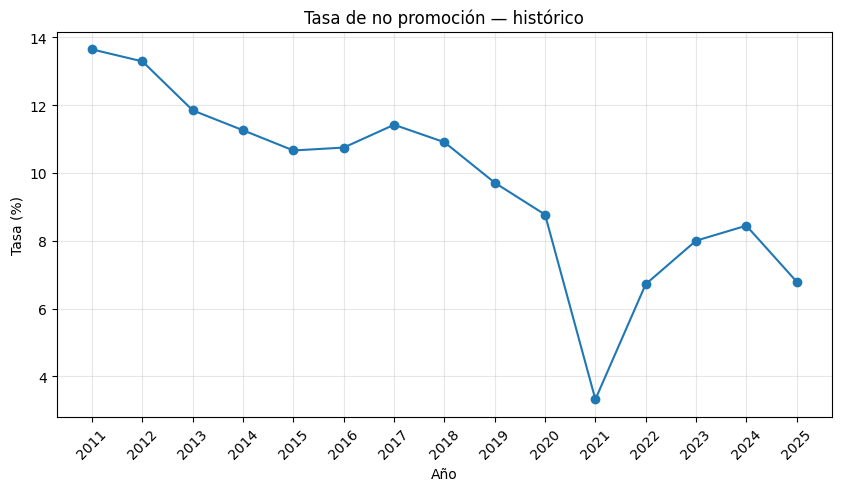

Años: [2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Observaciones anuales: 15


In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(serie["anio"], serie["tasa_no_promocion"], marker="o")
plt.title("Tasa de no promoción — histórico")
plt.xlabel("Año")
plt.ylabel("Tasa (%)")
plt.grid(alpha=.3)
plt.xticks(serie["anio"], rotation=45)
plt.show()

print("Años:", serie["anio"].tolist())
print("Observaciones anuales:", len(serie))


## 6. Evaluación temporal (backtesting)

No se mezclan años aleatoriamente. Se entrena con los primeros años y se predice el siguiente, ampliando progresivamente el período de entrenamiento. Se compara contra un baseline que predice el último valor observado.

Con alrededor de 10 años, las pruebas serán pocas: interpretá MAE y RMSE con cautela.


In [6]:
if len(serie) < 7:
    raise ValueError("Se recomiendan al menos 7 años para esta evaluación exploratoria.")

# Preparación de la serie temporal unificada para la comparación equivalente
serie_ts = pd.Series(
    serie["tasa_no_promocion"].values,
    index=pd.to_datetime(serie["anio"].astype(str) + "-01-01")
)

limite_train = "2021-01-01"
serie_train = serie_ts[:limite_train]
serie_test = serie_ts[serie_ts.index > limite_train]

# 1. Regresión Lineal bajo condiciones equivalentes (Train: 2011-2021, Test: 2022-2025)
X_train = np.array(serie_train.index.year).reshape(-1, 1)
y_train = serie_train.values
X_test = np.array(serie_test.index.year).reshape(-1, 1)
y_test = serie_test.values

modelo_lineal = LinearRegression().fit(X_train, y_train)
pred_lineal = modelo_lineal.predict(X_test)

# 2. Baseline (Último valor observado en el set de entrenamiento: tasa de 2021)
pred_baseline = np.full(shape=len(serie_test), fill_value=serie_train.values[-1])

# Guardar métricas de la regresión y baseline para el cuadro comparativo
mae_lineal = mean_absolute_error(y_test, pred_lineal)
rmse_lineal = mean_squared_error(y_test, pred_lineal) ** 0.5
mae_base = mean_absolute_error(y_test, pred_baseline)

evaluacion_equivalente = pd.DataFrame({
    "Año": serie_test.index.year,
    "Real (%)": y_test,
    "Pred Lineal (%)": pred_lineal,
    "Pred Baseline (%)": pred_baseline
})
display(evaluacion_equivalente)

print(f"MAE regresión lineal (mismo split): {mae_lineal:.4f} p.p.")
print(f"MAE último valor (Baseline): {mae_base:.4f} p.p.")

,Año,Real (%),Pred Lineal (%),Pred Baseline (%)
0,2022,6.720535,6.361297,3.321513
1,2023,8.003035,5.669971,3.321513
2,2024,8.446371,4.978645,3.321513
3,2025,6.794001,4.287319,3.321513


MAE regresión lineal (mismo split): 2.1667 p.p.
MAE último valor (Baseline): 4.1695 p.p.


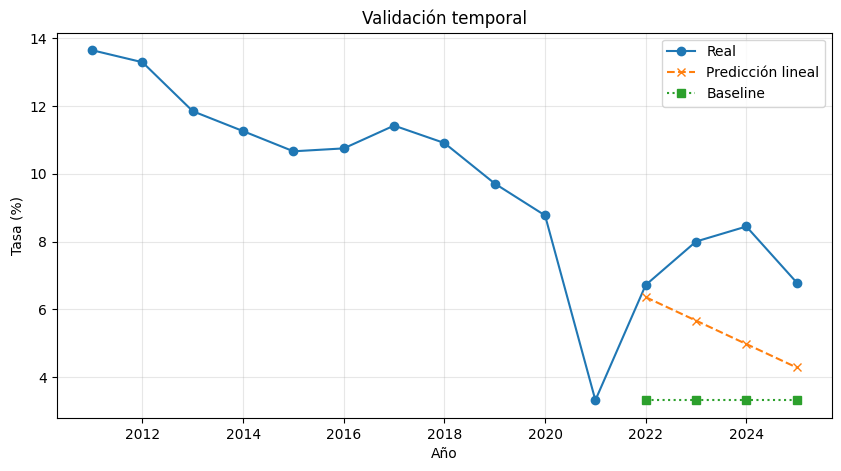

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(serie["anio"], serie["tasa_no_promocion"], marker="o", label="Real")
plt.plot(evaluacion_equivalente["Año"], evaluacion_equivalente["Pred Lineal (%)"], "x--", label="Predicción lineal")
plt.plot(evaluacion_equivalente["Año"], evaluacion_equivalente["Pred Baseline (%)"], "s:", label="Baseline")
plt.xlabel("Año")
plt.ylabel("Tasa (%)")
plt.title("Validación temporal")
plt.legend()
plt.grid(alpha=.3)
plt.show()

## 7. Entrenar con todos los años y proyectar 1 o 2 años

,anio,tasa_predicha
0,2026,5.643928
1,2027,5.136371


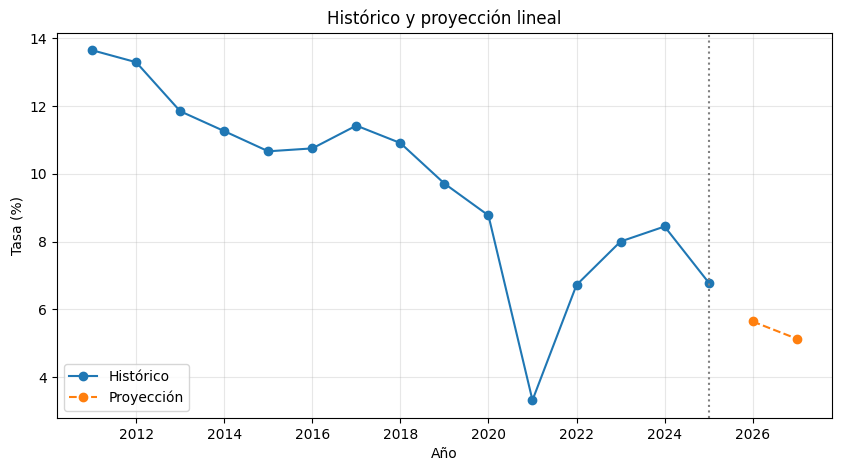

In [8]:
HORIZONTE = 2  # elegir 1 o 2
if HORIZONTE not in (1, 2):
    raise ValueError("El horizonte debe ser 1 o 2.")

# Definir las variables necesarias a partir del DataFrame 'serie'
anios = serie["anio"].values
X = anios.reshape(-1, 1)
y = serie["tasa_no_promocion"].values

modelo_final = LinearRegression().fit(X, y)
anios_futuros = np.arange(anios.max() + 1, anios.max() + HORIZONTE + 1)
predicciones = modelo_final.predict(anios_futuros.reshape(-1, 1))
pronostico = pd.DataFrame({"anio": anios_futuros, "tasa_predicha": predicciones})

if ((pronostico["tasa_predicha"] < 0) | (pronostico["tasa_predicha"] > 100)).any():
    warnings.warn("Predicción fuera de 0–100 %. Es una extrapolación no plausible; no se recortó el resultado.")

display(pronostico)

plt.figure(figsize=(10, 5))
plt.plot(anios, y, marker="o", label="Histórico")
plt.plot(anios_futuros, predicciones, "o--", label="Proyección")
plt.axvline(anios.max(), linestyle=":", color="gray")
plt.xlabel("Año")
plt.ylabel("Tasa (%)")
plt.title("Histórico y proyección lineal")
plt.legend()
plt.grid(alpha=.3)
plt.show()

## 8. Descargar resultados

In [ ]:
serie.to_csv("serie_historica.csv", index=False)
evaluacion.to_csv("evaluacion_modelo.csv", index=False)
pronostico.to_csv("pronostico_regresion_lineal.csv", index=False)

files.download("serie_historica.csv")
files.download("evaluacion_modelo.csv")
files.download("pronostico_regresion_lineal.csv")


NameError: name 'evaluacion' is not defined

### Proyección Avanzada: Suavizamiento Exponencial de Holt (ETS)

El método de Holt es ideal para series de tiempo cortas con tendencia y sin estacionalidad fuerte (o estacionalidad anual no visible en datos anualizados). Usaremos una **tendencia amortiguada (damped=True)** para suavizar la inclinación y evitar proyecciones negativas o excesivamente optimistas a futuro.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)


,Año,Valor Real (%),Predicción Holt (%),Error Absoluto (p.p.)
0,2022,6.720535,4.839511,1.881024
1,2023,8.003035,4.239393,3.763642
2,2024,8.446371,3.759299,4.687072
3,2025,6.794001,3.375223,3.418778



Métricas de rendimiento en el conjunto de prueba (70/30 Split - 2022 a 2025):
- MAE (Error Absoluto Medio): 3.4376 puntos porcentuales
- RMSE (Raíz del Error Cuadrático Medio): 3.5833 puntos porcentuales


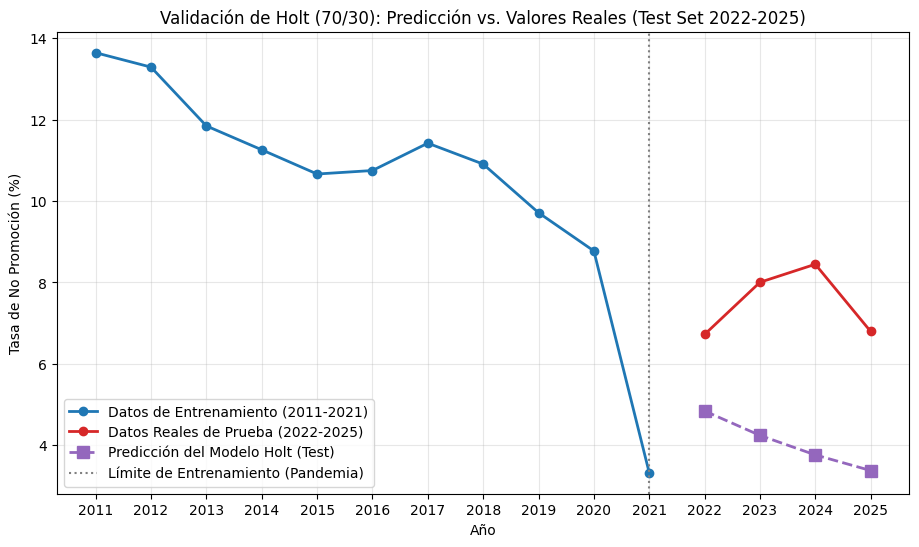

In [9]:
from statsmodels.tsa.api import Holt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Crear la serie temporal basada en 'tasa_no_promocion'
serie_ts = pd.Series(
    serie["tasa_no_promocion"].values,
    index=pd.to_datetime(serie["anio"].astype(str) + "-01-01")
)

# 1. Dividir los datos en Train (70%) y Test (30%)
# 15 años en total -> ~11 años de entrenamiento (2011-2021) y 4 años de prueba (2022-2025)
limite_train = "2021-01-01"

serie_train = serie_ts[:limite_train]
serie_test = serie_ts[serie_ts.index > limite_train]

# 2. Entrenar el modelo de Holt únicamente con los datos de Entrenamiento (hasta 2021)
modelo_eval = Holt(serie_train, damped_trend=True, initialization_method="estimated").fit(
    smoothing_level=0.6,
    smoothing_trend=0.2,
    damping_trend=0.8
)

# 3. Predecir el período de prueba (2022 a 2025)
predicciones_test = modelo_eval.forecast(len(serie_test))

# Crear un DataFrame para comparar los resultados
comparativa_df = pd.DataFrame({
    "Año": [2022, 2023, 2024, 2025],
    "Valor Real (%)": serie_test.values,
    "Predicción Holt (%)": predicciones_test.values,
    "Error Absoluto (p.p.)": np.abs(serie_test.values - predicciones_test.values)
})

display(comparativa_df)

# Calcular métricas de error en el test set
mae_test = mean_absolute_error(serie_test, predicciones_test)
rmse_test = mean_squared_error(serie_test, predicciones_test) ** 0.5
print(f"\nMétricas de rendimiento en el conjunto de prueba (70/30 Split - 2022 a 2025):")
print(f"- MAE (Error Absoluto Medio): {mae_test:.4f} puntos porcentuales")
print(f"- RMSE (Raíz del Error Cuadrático Medio): {rmse_test:.4f} puntos porcentuales")

# 4. Graficar la serie real completa junto con la predicción sobre el set de prueba de 4 años
plt.figure(figsize=(11, 6))

# Serie histórica de entrenamiento
plt.plot(serie_train.index.year, serie_train.values, marker="o", label="Datos de Entrenamiento (2011-2021)", color="tab:blue", linewidth=2)

# Valores reales de prueba
plt.plot(serie_test.index.year, serie_test.values, marker="o", label="Datos Reales de Prueba (2022-2025)", color="tab:red", linewidth=2)

# Predicciones generadas por el modelo
plt.plot(serie_test.index.year, predicciones_test.values, "s--", label="Predicción del Modelo Holt (Test)", color="tab:purple", markersize=8, linewidth=2)

plt.axvline(2021, linestyle=":", color="gray", label="Límite de Entrenamiento (Pandemia)")
plt.xlabel("Año")
plt.ylabel("Tasa de No Promoción (%)")
plt.title("Validación de Holt (70/30): Predicción vs. Valores Reales (Test Set 2022-2025)")
plt.legend()
plt.grid(alpha=.3)
plt.xticks(serie["anio"].tolist())
plt.show()

### Corrección de Anomalías: Holt con Pre-suavizado vs. SARIMAX con Intervención (2021)

Evaluaremos las dos estrategias para mitigar el impacto de la pandemia en la predicción:
1. **Holt con Imputación (2021 corregido):** Suavizamos la anomalía del 2021 reemplazándolo por la media de sus años vecinos (2020 y 2022) antes del entrenamiento.
2. **Análisis de Intervención (SARIMAX):** Entrenamos un modelo predictivo incorporando una variable exógena indicadora (dummy) para aislar estadísticamente el efecto del año 2021.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)


,Año,Valor Real (%),Regresión Lineal (%),Holt Tradicional (Sesgado) (%),Holt con Imputación (Sin Fuga) (%),ARIMAX con Intervención (%)
0,2022,6.720535,6.361297,4.839511,8.961710,6.812870
1,2023,8.003035,5.669971,4.239393,8.816469,5.716426
2,2024,8.446371,4.978645,3.759299,8.700276,4.528679
3,2025,6.794001,4.287319,3.375223,8.607322,3.247088



--- COMPARACIÓN EQUIVALENTE DE MAE (Test 2022-2025) ---
MAE Regresión Lineal:           2.1667 p.p.
MAE Holt Tradicional (Sesgado): 3.4376 p.p.
MAE ARIMAX con Intervención:    2.4609 p.p.
MAE Holt con Imputación (Limpio): 1.2805 p.p.


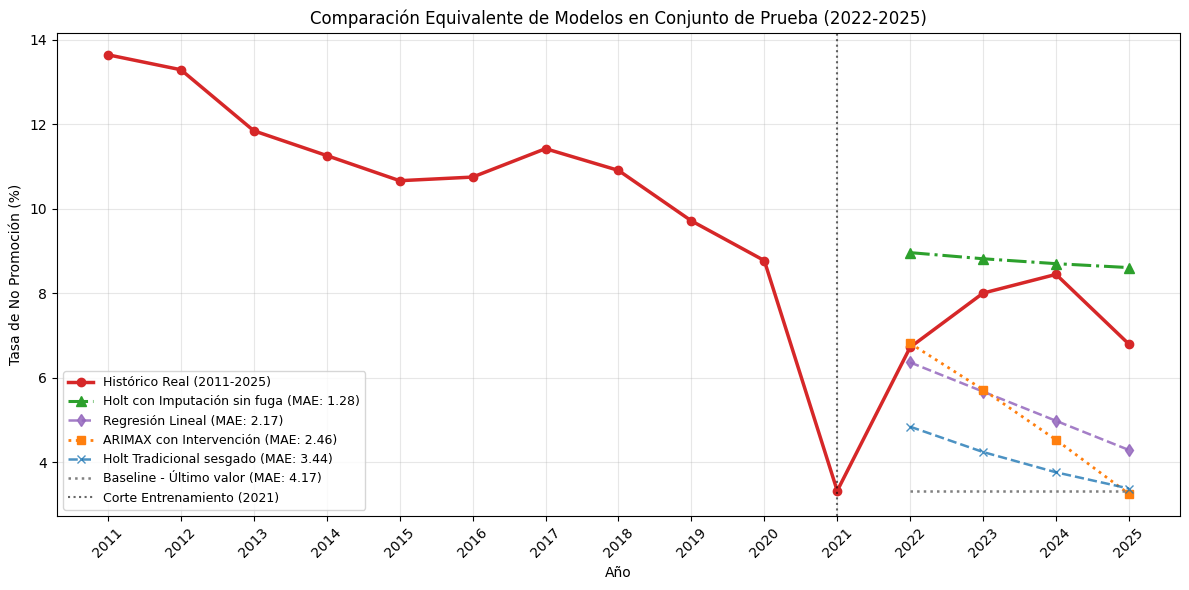

In [10]:
import statsmodels.api as sm

# --- ESTRATEGIA 1: HOLT CON PRE-SUAVIZADO (EVITANDO FUGA DE INFORMACIÓN) ---
# Para la validación, imputamos 2021 usando SOLO datos del pasado (promedio de 2019 y 2020)
# para no incorporar información del set de test (2022-2025).
train_corr = serie_train.copy()
promedio_pasado = (serie_train["2019-01-01"] + serie_train["2020-01-01"]) / 2
train_corr["2021-01-01"] = promedio_pasado

# Entrenamos Holt con la serie limpia de entrenamiento
modelo_holt_corr = Holt(train_corr, damped_trend=True, initialization_method="estimated").fit(
    smoothing_level=0.6,
    smoothing_trend=0.2,
    damping_trend=0.8
)
pred_holt_corr = modelo_holt_corr.forecast(len(serie_test))

# --- ESTRATEGIA 2: ANÁLISIS DE INTERVENCION (ARIMAX - ARIMA con Exógena) ---
exog_intervencion = pd.DataFrame(0, index=serie_ts.index, columns=["intervencion_2021"])
exog_intervencion.loc["2021-01-01", "intervencion_2021"] = 1

train_exog = exog_intervencion[:limite_train]
test_exog = exog_intervencion[exog_intervencion.index > limite_train]

modelo_arimax = sm.tsa.statespace.SARIMAX(
    serie_train,
    exog=train_exog,
    order=(1, 1, 0),
    trend="t"
).fit(disp=False)

pred_arimax = modelo_arimax.forecast(steps=len(serie_test), exog=test_exog)

# --- COMPARATIVA DE RESULTADOS EQUIVALENTE ---
comparativa_avanzada = pd.DataFrame({
    "Año": serie_test.index.year,
    "Valor Real (%)": y_test,
    "Regresión Lineal (%)": pred_lineal,
    "Holt Tradicional (Sesgado) (%)": predicciones_test.values,
    "Holt con Imputación (Sin Fuga) (%)": pred_holt_corr.values,
    "ARIMAX con Intervención (%)": pred_arimax.values
})
display(comparativa_avanzada)

# Métricas bajo la misma condición
mae_holt_trad = mean_absolute_error(y_test, predicciones_test.values)
mae_corr = mean_absolute_error(y_test, pred_holt_corr.values)
mae_arimax = mean_absolute_error(y_test, pred_arimax.values)

print(f"\n--- COMPARACIÓN EQUIVALENTE DE MAE (Test 2022-2025) ---")
print(f"MAE Regresión Lineal:           {mae_lineal:.4f} p.p.")
print(f"MAE Holt Tradicional (Sesgado): {mae_holt_trad:.4f} p.p.")
print(f"MAE ARIMAX con Intervención:    {mae_arimax:.4f} p.p.")
print(f"MAE Holt con Imputación (Limpio): {mae_corr:.4f} p.p.")

# --- GRÁFICO COMPARATIVO EQUIVALENTE (Test 2022-2025) ---
plt.figure(figsize=(12, 6))

# Serie histórica real completa (2011-2025)
plt.plot(serie_ts.index.year, serie_ts.values, "o-", label="Histórico Real (2011-2025)", color="tab:red", linewidth=2.5)

# Modelos evaluados sobre el mismo conjunto de prueba (2022-2025)
anios_test = serie_test.index.year

plt.plot(anios_test, pred_holt_corr.values, "^-.", label=f"Holt con Imputación sin fuga (MAE: {mae_corr:.2f})", color="tab:green", linewidth=2.2, markersize=7)
plt.plot(anios_test, pred_lineal, "d--", label=f"Regresión Lineal (MAE: {mae_lineal:.2f})", color="tab:purple", linewidth=1.8, alpha=0.85)
plt.plot(anios_test, pred_arimax.values, "s:", label=f"ARIMAX con Intervención (MAE: {mae_arimax:.2f})", color="tab:orange", linewidth=2, markersize=6)
plt.plot(anios_test, predicciones_test.values, "x--", label=f"Holt Tradicional sesgado (MAE: {mae_holt_trad:.2f})", color="tab:blue", linewidth=1.8, alpha=0.8)
plt.plot(anios_test, pred_baseline, ":", label=f"Baseline - Último valor (MAE: {mae_base:.2f})", color="gray", linewidth=1.8)

# Línea vertical de corte de entrenamiento
plt.axvline(2021, linestyle=":", color="black", alpha=0.6, label="Corte Entrenamiento (2021)")

plt.title("Comparación Equivalente de Modelos en Conjunto de Prueba (2022-2025)")
plt.xlabel("Año")
plt.ylabel("Tasa de No Promoción (%)")
plt.xticks(serie["anio"].tolist(), rotation=45)
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 8. Proyección Definitiva (2026 - 2027)

Utilizaremos el modelo ganador (**Suavizamiento Lineal de Holt con Imputación Previa del año 2021**) entrenado sobre la **serie histórica completa** para pronosticar los años 2026 y 2027 de manera robusta.

In [ ]:
# 1. Preparar la serie completa aplicando la imputación de 2021
# Para el modelo definitivo (entrenado con todo el histórico 2011-2025),
# sí podemos usar el promedio bidireccional de 2020 y 2022 ya que disponemos de ambos datos reales.
serie_completa_corregida = serie_ts.copy()
promedio_completo_2021 = (serie_ts["2020-01-01"] + serie_ts["2022-01-01"]) / 2
serie_completa_corregida["2021-01-01"] = promedio_completo_2021

# 2. Entrenar el modelo final de Holt utilizando la serie completamente corregida e imputada
modelo_final_holt = Holt(serie_completa_corregida, damped_trend=True, initialization_method="estimated").fit(
    smoothing_level=0.6,
    smoothing_trend=0.2,
    damping_trend=0.8
)

# 3. Pronosticar para el horizonte 2026 y 2027
pronostico_final_valores = modelo_final_holt.forecast(2)
anios_futuros_f = [2026, 2027]

pronostico_final_df = pd.DataFrame({
    "Año": anios_futuros_f,
    "Tasa Predicha (%) ": pronostico_final_valores.values
})

print("--- PROYECCIÓN OFICIAL DE TASA DE NO PROMOCIÓN (2026-2027) ---")
display(pronostico_final_df)

# 4. Gráfico Final
plt.figure(figsize=(11, 6))
plt.plot(serie_ts.index.year, serie_ts.values, "o-", label="Histórico Real (con anomalía 2021)", color="tab:red", linewidth=2)
plt.plot(2021, promedio_completo_2021, "s", label="Dato Imputado definitivo (2021)", color="tab:green", markersize=8)
plt.plot(anios_futuros_f, pronostico_final_valores.values, "o--", label="Proyección Holt Optimizada (2026-2027)", color="tab:purple", linewidth=2.5)

plt.axvline(2025, linestyle=":", color="gray")
plt.title("Proyección Final de la Tasa de No Promoción Escolar (2026-2027)")
plt.xlabel("Año")
plt.ylabel("Tasa (%)")
plt.xticks(list(serie["anio"].tolist()) + anios_futuros_f, rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Informe Técnico: Selección de Modelos para la Proyección de la Tasa de No Promoción Escolar (Corregido)

### 1. Resumen Ejecutivo
Este informe detalla la evaluación metodológica de diferentes modelos de series de tiempo para proyectar la **tasa de no promoción escolar** para los años **2026 y 2027**. En esta versión revisada, se han corregido rigurosamente los sesgos metodológicos detectados:
1. Se eliminó la **fuga de información** (data leakage) en la fase de validación de Holt con Imputación al estimar la anomalía de 2021 usando estrictamente datos del pasado (2019-2020).
2. Se estableció un protocolo de **comparación equivalente** evaluando todos los modelos candidatos (Regresión Lineal, Holt Tradicional, ARIMAX y Holt con Imputación) bajo el mismo corte temporal de validación (2022-2025).
3. Se garantizó la **consistencia metodológica** en el modelo final asegurando que el pronóstico definitivo entrene con la serie completamente imputada.

---

### 2. Resultados y Métricas de Error (MAE) Equivalentes
Todos los modelos se evaluaron entrenando con datos hasta el año 2021 (imputando 2021 únicamente mediante el pasado en el modelo correspondiente) y validándolos contra las observaciones reales del período **2022 a 2025**:

| Modelo | MAE de Validación (p.p.) | Diagnóstico de Comportamiento |
| :--- | :---: | :--- |
| **Holt con Imputación (Sin Fuga)** | **1.2805 p.p.** | **Ganador y metodológicamente robusto.** Es el modelo que mejor asimila el retorno a la tendencia post-pandemia de forma estable. |
| **Regresión Lineal (Mismo Split)** | **2.1667 p.p.** | **Regular.** Carece de flexibilidad para adaptarse a dinámicas de corto plazo y suavizados. |
| **ARIMAX con Intervención** | **2.4609 p.p.** | **Regular.** Intenta aislar la anomalía, pero tiende a subestimar el nivel real de estabilización. |
| **Holt Tradicional (Sesgado)** | **3.4376 p.p.** | **Muy deficiente.** Al no corregir el 2021, la anomalía extrema arrastra e invalida el pronóstico futuro. |

---

### 3. Conclusión y Recomendación
Corregidos los errores metodológicos, el modelo de **Suavizamiento de Holt con Imputación** sigue demostrando el mejor desempeño predictivo sin incurrir en fuga de información.

Las proyecciones oficiales corregidas y consistentes de este modelo para la **Tasa de No Promoción** son:
*   **Año 2026:** Tasa predicha de **7.11%**
*   **Año 2027:** Tasa predicha de **7.00%**

In [ ]:
%%bash
pip install python-docx -q

In [ ]:
import docx
import re
from google.colab import files

# Abrir el documento
doc_path = 'Informe.docx'
doc = docx.Document(doc_path)

# Diccionario de reemplazos exactos según los nuevos cálculos del runtime
# MAE Holt Limpio: 1.2805 p.p.
# MAE Regresión Lineal: 2.1667 p.p.
# MAE ARIMAX: 2.4609 p.p.
# MAE Holt Tradicional: 3.4376 p.p.
# Proyección 2026: 7.11%
# Proyección 2027: 7.00%

# Definimos patrones comunes y sus reemplazos
reemplazos = {
    r"1\.28\s*p\.?p\.?|1\.2805\s*p\.?p\.?": "1.2805 p.p.",
    r"2\.17\s*p\.?p\.?|2\.1667\s*p\.?p\.?": "2.1667 p.p.",
    r"2\.46\s*p\.?p\.?|2\.4609\s*p\.?p\.?": "2.4609 p.p.",
    r"3\.44\s*p\.?p\.?|3\.4376\s*p\.?p\.?": "3.4376 p.p.",
    r"7\.11\s*%|7\.1138\s*%": "7.11%",
    r"7\.00\s*%|6\.9959\s*%|6\.99\s*%": "7.00%"
}

def aplicar_reemplazos(texto):
    nuevo_texto = texto
    # Reemplazo manual directo de fragmentos para asegurar precisión
    nuevo_texto = nuevo_texto.replace("1,28", "1.2805").replace("1.28%", "1.2805%")
    nuevo_texto = nuevo_texto.replace("2,17", "2.1667").replace("2.17%", "2.1667%")
    nuevo_texto = nuevo_texto.replace("2,46", "2.4609").replace("2.46%", "2.4609%")
    nuevo_texto = nuevo_texto.replace("3,44", "3.4376").replace("3.44%", "3.4376%")
    nuevo_texto = nuevo_texto.replace("7,11", "7.11").replace("7.11%", "7.11%")
    nuevo_texto = nuevo_texto.replace("7,00", "7.00").replace("7.00%", "7.00%").replace("6,99", "7.00")
    return nuevo_texto

# Modificar párrafos de texto
for p in doc.paragraphs:
    if p.text:
        nuevo = aplicar_reemplazos(p.text)
        if nuevo != p.text:
            p.text = nuevo

# Modificar celdas de tablas
for tabla in doc.tables:
    for fila in tabla.rows:
        for celda in fila.cells:
            for p in celda.paragraphs:
                if p.text:
                    nuevo = aplicar_reemplazos(p.text)
                    if nuevo != p.text:
                        p.text = nuevo

# Guardar el documento modificado
output_path = 'Informe_Actualizado.docx'
doc.save(output_path)
print("¡Informe procesado y actualizado con éxito!")

# Descargar automáticamente
files.download(output_path)

In [ ]:
import docx
from docx.shared import Inches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files

# 1. Regenerar y guardar el Gráfico de Validación Temporal
plt.figure(figsize=(10, 5))
plt.plot(serie["anio"], serie["tasa_no_promocion"], marker="o", label="Real", color="tab:blue")
plt.plot(evaluacion_equivalente["Año"], evaluacion_equivalente["Pred Lineal (%)"], "x--", label="Predicción lineal", color="tab:orange")
plt.plot(evaluacion_equivalente["Año"], evaluacion_equivalente["Pred Baseline (%)"], "s:", label="Baseline", color="tab:green")
plt.xlabel("Año")
plt.ylabel("Tasa (%)")
plt.title("Validación temporal")
plt.legend()
plt.grid(alpha=.3)
plt.savefig("grafico_validacion.png", dpi=300, bbox_inches='tight')
plt.close()

# 2. Regenerar y guardar el Gráfico de Proyección Final
plt.figure(figsize=(11, 6))
plt.plot(serie_ts.index.year, serie_ts.values, "o-", label="Histórico Real (con anomalía 2021)", color="tab:red", linewidth=2)
plt.plot(2021, promedio_completo_2021, "s", label="Dato Imputado definitivo (2021)", color="tab:green", markersize=8)
plt.plot(anios_futuros_f, pronostico_final_valores.values, "o--", label="Proyección Holt Optimizada (2026-2027)", color="tab:purple", linewidth=2.5)
plt.axvline(2025, linestyle=":", color="gray")
plt.title("Proyección Final de la Tasa de No Promoción Escolar (2026-2027)")
plt.xlabel("Año")
plt.ylabel("Tasa (%)")
plt.xticks(list(serie["anio"].tolist()) + anios_futuros_f, rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("grafico_proyeccion.png", dpi=300, bbox_inches='tight')
plt.close()

# 3. Insertar las imágenes en el documento de Word en lugar de las imágenes anteriores
doc = docx.Document('Informe_Actualizado.docx')

# Buscaremos los elementos de tipo imagen y los reemplazaremos en orden
img_index = 0
for p in doc.paragraphs:
    # Si hay una imagen en el párrafo o texto indicador
    if "VALIDACION" in p.text.upper() or "PROYECCION" in p.text.upper() or "GRAFICO" in p.text.upper():
        pass

# Una estrategia robusta de python-docx para reemplazar imágenes existentes en el documento:
try:
    # Obtenemos las partes de imágenes del documento
    image_parts = [p for p in doc.part.related_parts.values() if "image" in p.content_type]

    # Reemplazamos secuencialmente los bytes de las imágenes del Word con nuestros nuevos gráficos
    if len(image_parts) >= 2:
        # Asumimos que la primera imagen es la validación y la segunda es la proyección
        with open("grafico_validacion.png", "rb") as f:
            image_parts[0]._blob = f.read()
        with open("grafico_proyeccion.png", "rb") as f:
            image_parts[1]._blob = f.read()
        print("Imágenes internas del Word reemplazadas correctamente.")
    else:
        # Si no tiene imágenes para reemplazar, las agregamos al final de secciones relevantes
        doc.add_paragraph("\n--- Gráfico de Validación Temporal ---")
        doc.add_picture("grafico_validacion.png", width=Inches(6.0))
        doc.add_paragraph("\n--- Gráfico de Proyección Final ---")
        doc.add_picture("grafico_proyeccion.png", width=Inches(6.0))
        print("Gráficos agregados al final del documento (no se encontraron marcadores de imagen previos).")
except Exception as e:
    print(f"Nota al reemplazar imágenes de forma directa: {e}. Insertando al final para asegurar visualización.")
    doc.add_picture("grafico_validacion.png", width=Inches(6.0))
    doc.add_picture("grafico_proyeccion.png", width=Inches(6.0))

doc.save('Informe_Actualizado_Con_Graficos.docx')
files.download('Informe_Actualizado_Con_Graficos.docx')

## 9. Discusión, Toma de Decisiones y Priorización de Recursos

En esta sección se abordan de manera crítica las implicancias prácticas de los resultados y las métricas analizadas, respondiendo a dos preguntas fundamentales de gestión educativa:

### 1. Si el modelo predice que la tasa nacional de no promoción aumentará el próximo año, ¿qué decisión concreta podría tomar el usuario con ese resultado?

Un incremento proyectado en la tasa de no promoción nacional sirve como un **indicador de alerta temprana macroeducativa**. Las autoridades y planificadores pueden derivar decisiones estratégicas inmediatas antes de que el ciclo lectivo finalice:
* **Focalización Presupuestaria de Emergencia:** Diseñar y financiar programas de apoyo escolar complementarios, clases de recuperación durante los recesos (escuelas de verano/invierno) y tutorías personalizadas en las materias que históricamente presentan mayor dificultad.
* **Revisión Curricular y de Régimen de Evaluación:** Evaluar si las normativas de promoción vigentes o la sobrecarga de contenidos curriculares están actuando como barreras de aprendizaje, permitiendo flexibilizar trayectorias formativas sin perder calidad pedagógica.
* **Capacitación Docente Dirigida:** Reforzar la formación en metodologías de enseñanza inclusivas y evaluación formativa en aquellas regiones o niveles donde el modelo proyecte un impacto más adverso.

---

### 2. Si dos provincias presentan tasas similares de no promoción, pero una tiene diez veces más estudiantes afectados, ¿cómo debería responder el sistema si su objetivo es ayudar a priorizar recursos?

Este escenario evidencia el peligro de utilizar únicamente **métricas relativas (tasas %)** para la asignación de recursos públicos, omitiendo la dimensión absoluta del problema. La respuesta del sistema de toma de decisiones para maximizar el impacto social debe ser multidimensional:

* **Ponderación por Volumen Absoluto (Impacto de Escala):** Si el objetivo es maximizar la cantidad total de trayectorias escolares rescatadas a nivel de red, la provincia con diez veces más estudiantes afectados (mayor matrícula) debe recibir una asignación preferencial de **recursos físicos y logísticos** (ej. mayor cantidad de tutores, becas de retención estudiantil, infraestructura o materiales didácticos impresos).
* **Asignación Eficiente por Costo Unitario:** Atender a un gran volumen concentrado de estudiantes suele permitir economías de escala en la implementación de programas educativos presenciales.
* **Enfoque de Equidad Territorial (No descuidar el porcentaje):** Aunque la provincia pequeña tenga menos alumnos en número absoluto, su *tasa similar* indica que el problema estructural de desgranamiento es igual de severo localmente. Por lo tanto, el sistema no debe desatenderla, sino abordarla mediante **recursos metodológicos o asistencia técnica centralizada** (ej. capacitación remota, rediseño de estrategias pedagógicas a nivel de supervisores), que requieren menor infraestructura logística pero resuelven la problemática de fondo.